# Hyperparametrien optimointi — Optuna

Tässä notebookissa haetaan parhaat hyperparametrit kaikille kolmelle mallille
(XGBoost, CatBoost, LightGBM) käyttäen **Optuna**-kirjastoa.

Optuna käyttää **TPE-algoritmin** (Tree-structured Parzen Estimator), joka on
Bayesilainen optimointimenetelmä: se oppii edellisistä kokeiluista ja
suuntaa haun lupaavimpiin parametrialueisiin pelkän satunnaisen haun sijaan.

## Rakenne

1. **Ympäristö ja data** — kirjastot, data, enkoodaus
2. **CatBoost-optimointi** — Optuna-haku, parhaat parametrit
3. **XGBoost-optimointi** — Optuna-haku, parhaat parametrit
4. **LightGBM-optimointi** — Optuna-haku, parhaat parametrit
5. **Tulosten vertailu** — mallien vertailu optimoiduilla parametreilla
6. **Johtopäätökset** — suositellut parametrit jatkokäyttöön

## 1. Ympäristö ja datan lataus

In [ ]:
import os
import gc
import subprocess
import warnings
from pathlib import Path
from dotenv import load_dotenv

import polars as pl
import numpy as np
import pandas as pd
import joblib
import optuna
from optuna.samplers import TPESampler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OrdinalEncoder

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import lightgbm as lgb

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# GPU-tarkistus
try:
    result = subprocess.run(["nvidia-smi"], capture_output=True, timeout=5)
    GPU_AVAILABLE = result.returncode == 0
except Exception:
    GPU_AVAILABLE = False

print(f"GPU available: {GPU_AVAILABLE}")

# ─────────────────────────────────────────────────────────────
# QUICK_TEST  True  = 100 k riviä  (nopea kehitys / debuggaus)
#             False = koko data (lopullinen ajo)
# ─────────────────────────────────────────────────────────────
QUICK_TEST = True

# Datan lataus
load_dotenv()
DATA_PATH = Path(os.getenv("DATA_PATH"))

train_df = pl.read_parquet(DATA_PATH / "train.parquet").to_pandas()
test_df  = pl.read_parquet(DATA_PATH / "test.parquet").to_pandas()

if QUICK_TEST:
    train_df = train_df.sample(n=100_000, random_state=42).reset_index(drop=True)
    test_df  = test_df.sample(n=20_000,  random_state=42).reset_index(drop=True)
    print(f"⚡ QUICK_TEST — osajoukkoa käytetään: Train {train_df.shape}, Test {test_df.shape}")
else:
    print(f"Train: {train_df.shape}, Test: {test_df.shape}")

GPU available: True
⚡ QUICK_TEST — osajoukkoa käytetään: Train (100000, 58), Test (20000, 58)


In [2]:
# Feature-setit
TARGET = "price"
ALL_TARGET_COLS = ["price"]
FEATURES = [c for c in train_df.columns if c not in ALL_TARGET_COLS]

X_train_raw = train_df[FEATURES].copy()
y_train     = train_df[TARGET]
X_test_raw  = test_df[FEATURES].copy()
y_test      = test_df[TARGET]

# Kategoristen sarakkeiden tunnistus
cat_cols = train_df[FEATURES].select_dtypes(include=["object", "category"]).columns.tolist()

# String-muunnos (yhtenevä CatBoostin kanssa)
X_train_str = X_train_raw.copy()
X_train_str[cat_cols] = X_train_str[cat_cols].fillna("missing").astype(str)

X_test_str = X_test_raw.copy()
X_test_str[cat_cols] = X_test_str[cat_cols].fillna("missing").astype(str)

# OrdinalEncoder XGBoost + LightGBM -malleille
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    encoded_missing_value=-2
)
encoder.fit(X_train_str[cat_cols])

X_train_enc = X_train_str.copy()
X_train_enc[cat_cols] = encoder.transform(X_train_str[cat_cols])

X_test_enc = X_test_str.copy()
X_test_enc[cat_cols] = encoder.transform(X_test_str[cat_cols])

print(f"Features: {len(FEATURES)}, kategorisia: {len(cat_cols)}")


# Apufunktiot
def eval_regression(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1, y_true))) * 100
    return {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape}


def plot_optuna_history(study, title):
    """Piirtää Optuna-haun kehityshistorian."""
    trials = study.trials_dataframe()
    trials = trials[trials["state"] == "COMPLETE"].reset_index(drop=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # RMSE per trial
    axes[0].plot(trials.index, trials["value"], marker="o", markersize=3,
                 color="#378ADD", alpha=0.7)
    axes[0].set_xlabel("Trial")
    axes[0].set_ylabel("Validation RMSE")
    axes[0].set_title(f"{title} — RMSE per trial")
    axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

    # Paras RMSE kumulatiivisesti
    best_so_far = trials["value"].cummin()
    axes[1].plot(trials.index, best_so_far, color="#1D9E75", linewidth=2)
    axes[1].set_xlabel("Trial")
    axes[1].set_ylabel("Paras RMSE tähän mennessä")
    axes[1].set_title(f"{title} — Konvergenssi")
    axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))

    plt.tight_layout()
    plt.show()
    print(f"Paras validation RMSE: ${study.best_value:,.2f}")
    print(f"Parhaat parametrit: {study.best_params}")

Features: 57, kategorisia: 12


## 2. CatBoost-optimointi

CatBoostille tärkeimmät hyperparametrit ovat:
- **`iterations`** — puiden lukumäärä (enemmän = parempi, mutta hitaampi)
- **`learning_rate`** — askeleen koko oppimisessa (pienempi = tarkempi, tarvitsee enemmän iteraatioita)
- **`depth`** — puiden maksimisyvyys (syvempi = monimutkaisempi malli, overfitting-riski)
- **`l2_leaf_reg`** — L2-regularisaatio (suurempi = yksinkertaisempi malli, vähemmän overfitting)
- **`bagging_temperature`** — bootstrap-näytteistyksen satunnaisuus
- **`random_strength`** — jakopisteiden satunnaisuus

  0%|          | 0/15 [00:00<?, ?it/s]

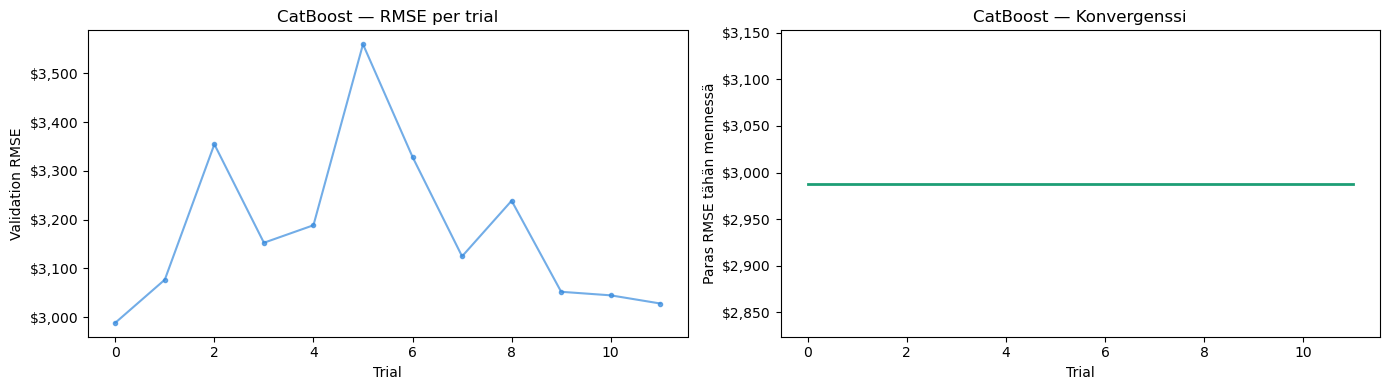

Paras validation RMSE: $2,988.24
Parhaat parametrit: {'iterations': 937, 'learning_rate': 0.1358198535217987, 'depth': 9, 'l2_leaf_reg': 3.968793330444372, 'bagging_temperature': 0.31203728088487304, 'random_strength': 0.8899863008405067}


In [3]:
N_TRIALS_CATBOOST = 15 if QUICK_TEST else 40    # enemmän = parempi tulos, kauemmin kestää
TIMEOUT_CATBOOST  = 600 if QUICK_TEST else 3600  # sekuntia (10 min / 1 tunti)

# Validointijakoko: 15% train-datasta
val_size = int(0.15 * len(X_train_str))
X_tr_cat, X_val_cat = X_train_str.iloc[:-val_size], X_train_str.iloc[-val_size:]
y_tr_cat, y_val_cat = y_train.iloc[:-val_size], y_train.iloc[-val_size:]


def catboost_objective(trial):
    params = {
        "iterations":         trial.suggest_int("iterations", 600, 1500),
        "learning_rate":      trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
        "depth":              trial.suggest_int("depth", 6, 10),
        "l2_leaf_reg":        trial.suggest_float("l2_leaf_reg", 1, 10, log=True),
        "bootstrap_type":     "Bayesian",
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
        "random_strength":    trial.suggest_float("random_strength", 0.5, 3.0),
        "loss_function":      "RMSE",
        "task_type":          "GPU" if GPU_AVAILABLE else "CPU",
        "verbose":            False,
        "random_seed":        42,
    }

    model = CatBoostRegressor(**params)
    model.fit(
        X_tr_cat, y_tr_cat,
        cat_features=cat_cols,
        eval_set=(X_val_cat, y_val_cat),
    )
    pred = model.predict(X_val_cat)
    return np.sqrt(mean_squared_error(y_val_cat, pred))


study_cb = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=42),
    study_name="catboost_price"
)
study_cb.optimize(
    catboost_objective,
    n_trials=N_TRIALS_CATBOOST,
    timeout=TIMEOUT_CATBOOST,
    show_progress_bar=True,
)

plot_optuna_history(study_cb, "CatBoost")

In [4]:
# Opetetaan lopullinen CatBoost koko train-datalla parhaillä parametreilla
best_cb_params = study_cb.best_params.copy()
best_cb_params.update({
    "bootstrap_type": "Bayesian",
    "loss_function":  "RMSE",
    "task_type":      "GPU" if GPU_AVAILABLE else "CPU",
    "verbose":        False,
    "random_seed":    42,
})

print("CatBoost — parhaat parametrit:")
for k, v in best_cb_params.items():
    print(f"  {k}: {v}")

model_cb = CatBoostRegressor(**best_cb_params)
model_cb.fit(X_train_str, y_train, cat_features=cat_cols)

pred_cb = model_cb.predict(X_test_str)
metrics_cb = eval_regression(y_test.values, pred_cb)

print("\nCatBoost — testijoukon metriikat (optimoidut parametrit):")
for k, v in metrics_cb.items():
    print(f"  {k}: {v:,.4f}")

CatBoost — parhaat parametrit:
  iterations: 937
  learning_rate: 0.1358198535217987
  depth: 9
  l2_leaf_reg: 3.968793330444372
  bagging_temperature: 0.31203728088487304
  random_strength: 0.8899863008405067
  bootstrap_type: Bayesian
  loss_function: RMSE
  task_type: GPU
  verbose: False
  random_seed: 42

CatBoost — testijoukon metriikat (optimoidut parametrit):
  MAE: 2,199.2191
  RMSE: 3,384.1551
  R2: 0.9564
  MAPE: 8.3578


## 3. XGBoost-optimointi

XGBoostille tärkeimmät hyperparametrit ovat:
- **`n_estimators`** — puiden lukumäärä
- **`learning_rate`** — oppimisvauhti
- **`max_depth`** — puiden maksimisyvyys
- **`subsample`** — satunnaisesti valittu osuus riveistä per puu
- **`colsample_bytree`** — satunnaisesti valittu osuus featureista per puu
- **`min_child_weight`** — minimipaino lehtisolmussa (regularisaatio)
- **`gamma`** — minimivoitto jaon tekemiseen (regularisaatio)
- **`reg_alpha`** / **`reg_lambda`** — L1/L2-regularisaatio

  0%|          | 0/15 [00:00<?, ?it/s]

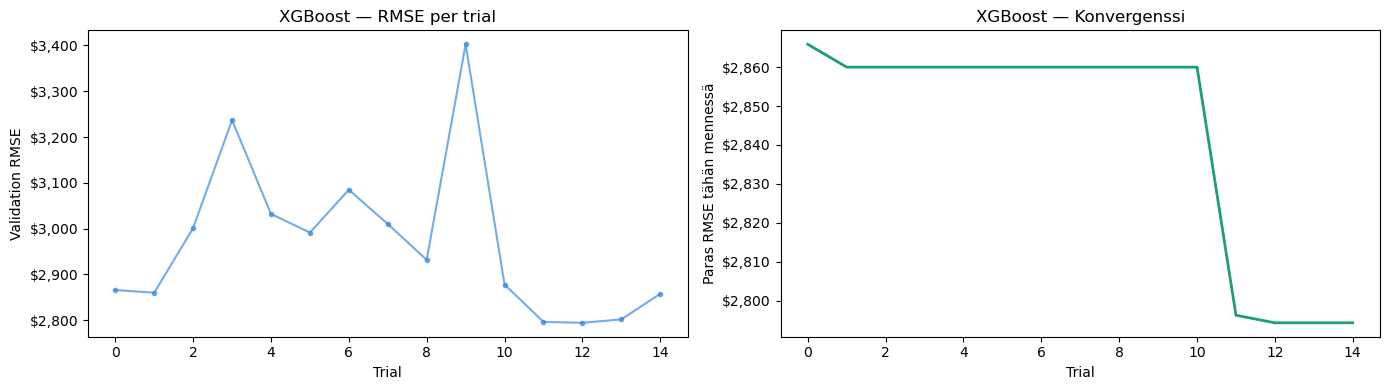

Paras validation RMSE: $2,794.30
Parhaat parametrit: {'n_estimators': 727, 'learning_rate': 0.06994464121244458, 'max_depth': 10, 'subsample': 0.9994636029283407, 'colsample_bytree': 0.7826041449135906, 'min_child_weight': 6, 'gamma': 0.18025999756161754, 'reg_alpha': 0.07427473300490671, 'reg_lambda': 0.15556988385316048}


In [5]:
N_TRIALS_XGB = 15 if QUICK_TEST else 40
TIMEOUT_XGB  = 600 if QUICK_TEST else 3600

X_tr_xgb, X_val_xgb = X_train_enc.iloc[:-val_size], X_train_enc.iloc[-val_size:]
y_tr_xgb, y_val_xgb = y_train.iloc[:-val_size], y_train.iloc[-val_size:]


def xgb_objective(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 800),
        "learning_rate":     trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
        "max_depth":         trial.suggest_int("max_depth", 5, 10),
        "subsample":         trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight":  trial.suggest_int("min_child_weight", 1, 20),
        "gamma":             trial.suggest_float("gamma", 0.0, 1.0),
        "reg_alpha":         trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda":        trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "tree_method":       "hist",
        "device":            "cuda" if GPU_AVAILABLE else "cpu",
        "random_state":      42,
        "n_jobs":            -1,
    }

    model = XGBRegressor(**params)
    model.fit(
        X_tr_xgb, y_tr_xgb,
        eval_set=[(X_val_xgb, y_val_xgb)],
        verbose=False,
    )
    pred = model.predict(X_val_xgb)
    return np.sqrt(mean_squared_error(y_val_xgb, pred))


study_xgb = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=42),
    study_name="xgboost_price"
)
study_xgb.optimize(
    xgb_objective,
    n_trials=N_TRIALS_XGB,
    timeout=TIMEOUT_XGB,
    show_progress_bar=True,
)

plot_optuna_history(study_xgb, "XGBoost")

In [6]:
best_xgb_params = study_xgb.best_params.copy()
best_xgb_params.update({
    "tree_method": "hist",
    "device":      "cuda" if GPU_AVAILABLE else "cpu",
    "random_state": 42,
    "n_jobs":      -1,
})

print("XGBoost — parhaat parametrit:")
for k, v in best_xgb_params.items():
    print(f"  {k}: {v}")

model_xgb = XGBRegressor(**best_xgb_params)
model_xgb.fit(X_train_enc, y_train)

pred_xgb = model_xgb.predict(X_test_enc)
metrics_xgb = eval_regression(y_test.values, pred_xgb)

print("\nXGBoost — testijoukon metriikat (optimoidut parametrit):")
for k, v in metrics_xgb.items():
    print(f"  {k}: {v:,.4f}")

XGBoost — parhaat parametrit:
  n_estimators: 727
  learning_rate: 0.06994464121244458
  max_depth: 10
  subsample: 0.9994636029283407
  colsample_bytree: 0.7826041449135906
  min_child_weight: 6
  gamma: 0.18025999756161754
  reg_alpha: 0.07427473300490671
  reg_lambda: 0.15556988385316048
  tree_method: hist
  device: cuda
  random_state: 42
  n_jobs: -1

XGBoost — testijoukon metriikat (optimoidut parametrit):
  MAE: 2,381.2398
  RMSE: 3,672.2661
  R2: 0.9487
  MAPE: 9.0841


## 4. LightGBM-optimointi

LightGBMille tärkeimmät hyperparametrit ovat:
- **`n_estimators`** — puiden lukumäärä
- **`learning_rate`** — oppimisvauhti
- **`num_leaves`** — lehtien maksimimäärä per puu (XGBoostin `max_depth`-analogia leaf-wise kasvussa)
- **`min_child_samples`** — minimirivimäärä lehtisolmussa
- **`subsample`** — riviosuus per puu
- **`colsample_bytree`** — feature-osuus per puu
- **`reg_alpha`** / **`reg_lambda`** — L1/L2-regularisaatio

  0%|          | 0/15 [00:00<?, ?it/s]

Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[497]	valid_0's l2: 7.98633e+06
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[678]	valid_0's l2: 9.1451e+06
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[443]	valid_0's l2: 8.09884e+06
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[565]	valid_0's l2: 8.06938e+06
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[250]	valid_0's l2: 8.13957e+06
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[297]	valid_0's l2: 1.09305e+07
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[637]	valid_0's l2: 8.58146e+06
Training until

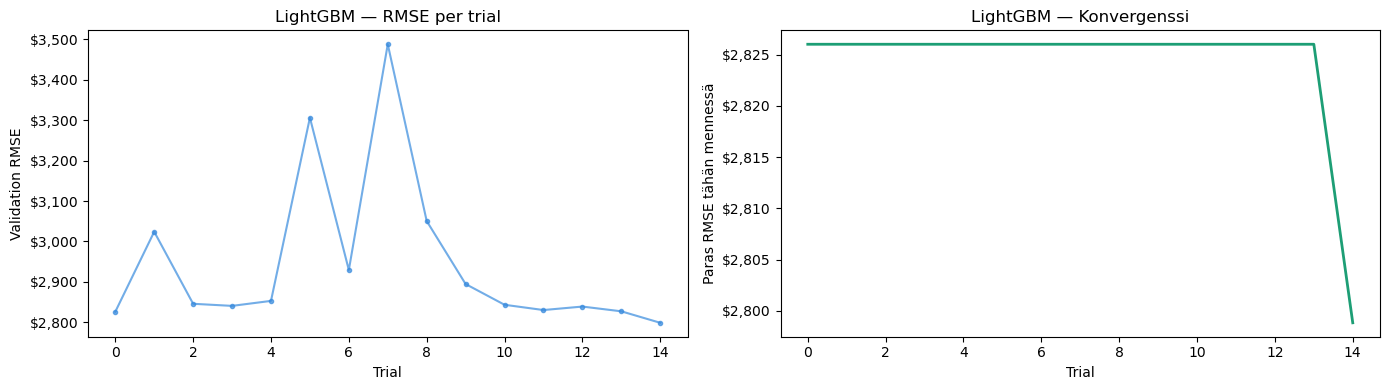

Paras validation RMSE: $2,798.82
Parhaat parametrit: {'n_estimators': 734, 'learning_rate': 0.07637755426888132, 'num_leaves': 196, 'min_child_samples': 36, 'subsample': 0.6630080698408224, 'colsample_bytree': 0.8565045669672156, 'reg_alpha': 0.020444372816806635, 'reg_lambda': 0.49033366371516013}


In [7]:
N_TRIALS_LGBM = 15 if QUICK_TEST else 40
TIMEOUT_LGBM  = 600 if QUICK_TEST else 3600

X_tr_lgbm, X_val_lgbm = X_train_enc.iloc[:-val_size], X_train_enc.iloc[-val_size:]
y_tr_lgbm, y_val_lgbm = y_train.iloc[:-val_size], y_train.iloc[-val_size:]


def lgbm_objective(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 1000),
        "learning_rate":     trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
        "num_leaves":        trial.suggest_int("num_leaves", 31, 256),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample":         trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha":         trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda":        trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "device":            "gpu" if GPU_AVAILABLE else "cpu",
        "random_state":      42,
        "n_jobs":            -1,
        "verbose":           -1,
    }

    model = lgb.LGBMRegressor(**params)
    model.fit(
        X_tr_lgbm, y_tr_lgbm,
        eval_set=[(X_val_lgbm, y_val_lgbm)],
        callbacks=[lgb.early_stopping(50), lgb.log_evaluation(-1)],
    )
    pred = model.predict(X_val_lgbm)
    return np.sqrt(mean_squared_error(y_val_lgbm, pred))


study_lgbm = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=42),
    study_name="lightgbm_price"
)
study_lgbm.optimize(
    lgbm_objective,
    n_trials=N_TRIALS_LGBM,
    timeout=TIMEOUT_LGBM,
    show_progress_bar=True,
)

plot_optuna_history(study_lgbm, "LightGBM")

In [8]:
best_lgbm_params = study_lgbm.best_params.copy()
best_lgbm_params.update({
    "device":      "gpu" if GPU_AVAILABLE else "cpu",
    "random_state": 42,
    "n_jobs":      -1,
    "verbose":     -1,
})

print("LightGBM — parhaat parametrit:")
for k, v in best_lgbm_params.items():
    print(f"  {k}: {v}")

model_lgbm = lgb.LGBMRegressor(**best_lgbm_params)
model_lgbm.fit(X_train_enc, y_train)

pred_lgbm = model_lgbm.predict(X_test_enc)
metrics_lgbm = eval_regression(y_test.values, pred_lgbm)

print("\nLightGBM — testijoukon metriikat (optimoidut parametrit):")
for k, v in metrics_lgbm.items():
    print(f"  {k}: {v:,.4f}")

LightGBM — parhaat parametrit:
  n_estimators: 734
  learning_rate: 0.07637755426888132
  num_leaves: 196
  min_child_samples: 36
  subsample: 0.6630080698408224
  colsample_bytree: 0.8565045669672156
  reg_alpha: 0.020444372816806635
  reg_lambda: 0.49033366371516013
  device: gpu
  random_state: 42
  n_jobs: -1
  verbose: -1

LightGBM — testijoukon metriikat (optimoidut parametrit):
  MAE: 2,308.8850
  RMSE: 3,565.5646
  R2: 0.9517
  MAPE: 8.7684


## 5. Tulosten vertailu

In [9]:
# Kootaan tulokset yhteen taulukkoon
comparison = pd.DataFrame([
    {"Malli": "CatBoost",  **{k: round(v, 4) for k, v in metrics_cb.items()}},
    {"Malli": "XGBoost",   **{k: round(v, 4) for k, v in metrics_xgb.items()}},
    {"Malli": "LightGBM",  **{k: round(v, 4) for k, v in metrics_lgbm.items()}},
]).set_index("Malli")

print("Optimoidut mallit — testijoukon vertailu")
display(comparison.style
    .highlight_min(subset=["MAE", "RMSE", "MAPE"], color="#d4edda")
    .highlight_max(subset=["R2"],                  color="#d4edda")
    .format({"MAE": "${:,.2f}", "RMSE": "${:,.2f}", "R2": "{:.4f}", "MAPE": "{:.2f}%"})
)

Optimoidut mallit — testijoukon vertailu


,MAE,RMSE,R2,MAPE
Malli,,,,
CatBoost,"$2,199.22","$3,384.16",0.9564,8.36%
XGBoost,"$2,381.24","$3,672.27",0.9487,9.08%
LightGBM,"$2,308.89","$3,565.56",0.9517,8.77%


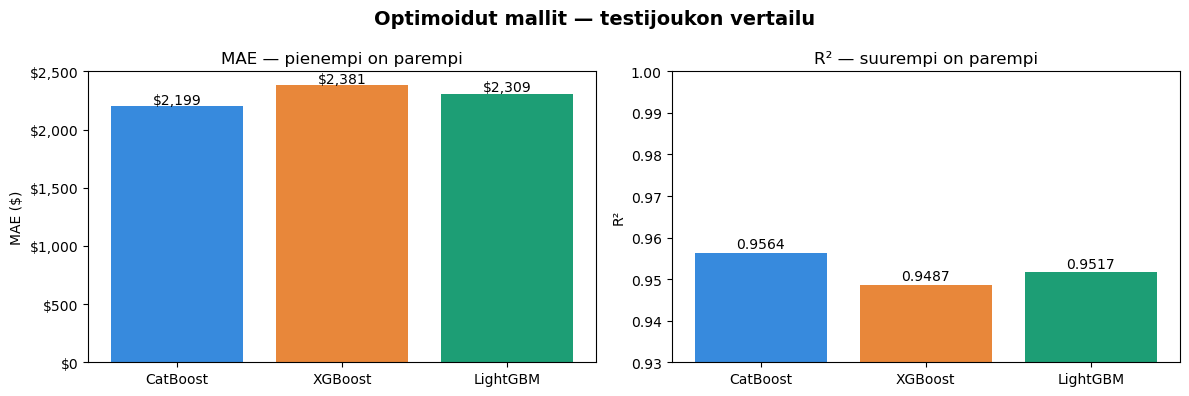

In [10]:
# Kuvaaja: MAE ja R² vertailu
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#378ADD", "#E8873A", "#1D9E75"]
models = comparison.index.tolist()

axes[0].bar(models, comparison["MAE"], color=colors)
axes[0].set_title("MAE — pienempi on parempi")
axes[0].set_ylabel("MAE ($)")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
for i, v in enumerate(comparison["MAE"]):
    axes[0].text(i, v + 20, f"${v:,.0f}", ha="center", fontsize=10)

axes[1].bar(models, comparison["R2"], color=colors)
axes[1].set_title("R² — suurempi on parempi")
axes[1].set_ylabel("R²")
axes[1].set_ylim(0.93, 1.0)
for i, v in enumerate(comparison["R2"]):
    axes[1].text(i, v + 0.001, f"{v:.4f}", ha="center", fontsize=10)

fig.suptitle("Optimoidut mallit — testijoukon vertailu", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Optimointihaun tärkeysanalyysi (parametrit)

Tarkastellaan mitkä hyperparametrit vaikuttivat eniten tulokseen.

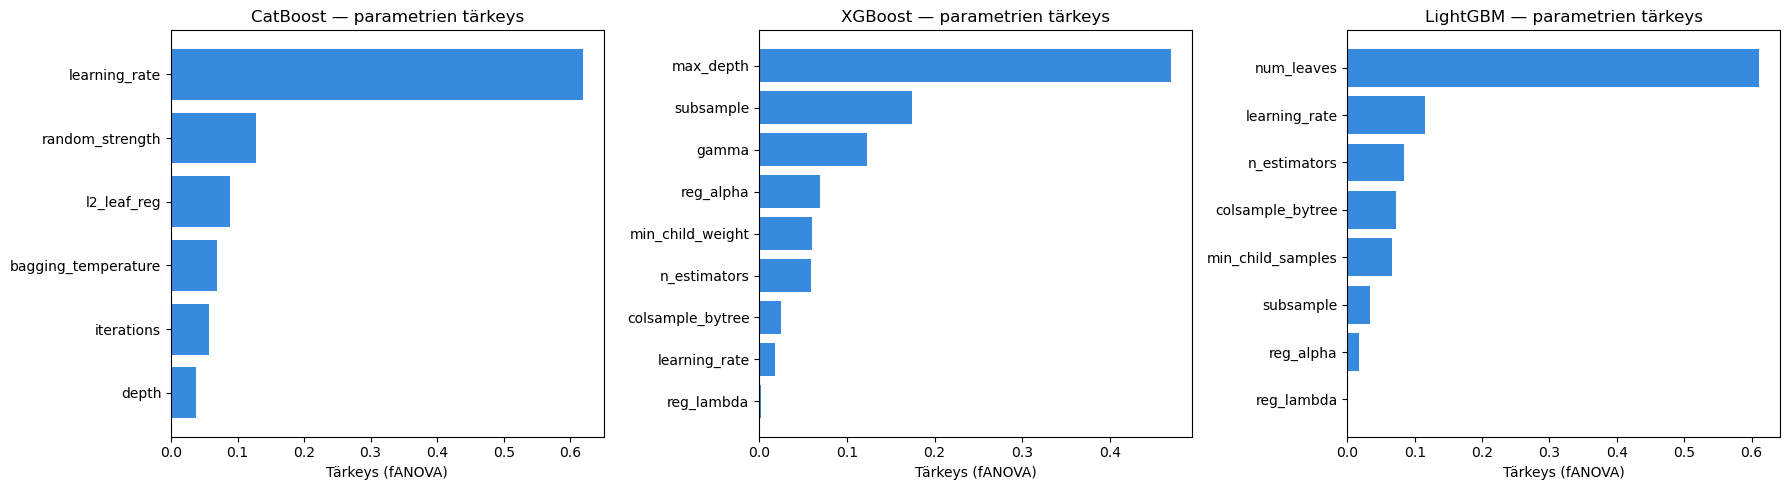

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (study, title) in zip(axes, [
    (study_cb,   "CatBoost"),
    (study_xgb,  "XGBoost"),
    (study_lgbm, "LightGBM"),
]):
    try:
        importances = optuna.importance.get_param_importances(study)
        params = list(importances.keys())
        vals   = list(importances.values())
        ax.barh(params[::-1], vals[::-1], color="#378ADD")
        ax.set_title(f"{title} — parametrien tärkeys")
        ax.set_xlabel("Tärkeys (fANOVA)")
    except Exception as e:
        ax.set_title(f"{title} — ei saatavilla ({e})")

plt.tight_layout()
plt.show()

## 7. Johtopäätökset

Alla on yhteenveto optimointiajon tuloksista ja suositellut parametrit
phase_4_results.ipynb -notebookin `MODEL_REGISTRY`-konfiguraatioon.

In [12]:
print("=" * 60)
print("YHTEENVETO — Suositellut parametrit MODEL_REGISTRY:iin")
print("=" * 60)

print("\n# CatBoost")
cb_final = {k: v for k, v in best_cb_params.items()
            if k not in ["bootstrap_type", "loss_function", "task_type", "verbose", "random_seed"]}
for k, v in cb_final.items():
    val = f"{v:.4f}" if isinstance(v, float) else str(v)
    print(f"    {k}={val},")

print("\n# XGBoost")
xgb_final = {k: v for k, v in best_xgb_params.items()
             if k not in ["tree_method", "device", "random_state", "n_jobs"]}
for k, v in xgb_final.items():
    val = f"{v:.4f}" if isinstance(v, float) else str(v)
    print(f"    {k}={val},")

print("\n# LightGBM")
lgbm_final = {k: v for k, v in best_lgbm_params.items()
              if k not in ["device", "random_state", "n_jobs", "verbose"]}
for k, v in lgbm_final.items():
    val = f"{v:.4f}" if isinstance(v, float) else str(v)
    print(f"    {k}={val},")

print("\n" + "=" * 60)
print("Paras malli:", comparison["RMSE"].idxmin())
print(f"  RMSE: ${comparison['RMSE'].min():,.2f}")
print(f"  MAE:  ${comparison['MAE'].min():,.2f}")
print(f"  R²:   {comparison['R2'].max():.4f}")

YHTEENVETO — Suositellut parametrit MODEL_REGISTRY:iin

# CatBoost
    iterations=937,
    learning_rate=0.1358,
    depth=9,
    l2_leaf_reg=3.9688,
    bagging_temperature=0.3120,
    random_strength=0.8900,

# XGBoost
    n_estimators=727,
    learning_rate=0.0699,
    max_depth=10,
    subsample=0.9995,
    colsample_bytree=0.7826,
    min_child_weight=6,
    gamma=0.1803,
    reg_alpha=0.0743,
    reg_lambda=0.1556,

# LightGBM
    n_estimators=734,
    learning_rate=0.0764,
    num_leaves=196,
    min_child_samples=36,
    subsample=0.6630,
    colsample_bytree=0.8565,
    reg_alpha=0.0204,
    reg_lambda=0.4903,

Paras malli: CatBoost
  RMSE: $3,384.16
  MAE:  $2,199.22
  R²:   0.9564
